## aims:


This document will load in the data from the 0dBm partition, then fit normalise each average element with it's S21 before averaging and fitting. 

This will provide a template going forward for analysis of a single data set

In [1]:
from DeviceClasses.E5063A_VNA_Class import VNA
from DeviceClasses.RS_FSW_new import FSW
from DeviceClasses.SMA100B import Signal_Generator
from DeviceClasses.Utilities.Fitting import fit_S21_peak, S21_eq, linear_voltage_to_dB, dBm_to_watts, watts_to_dBm, RMS_to_dBm, dBm_to_RMS,\
      fit_basic_S_ww_eq, basic_S_ww_eq, FWHM_guesser, find_closest_number,\
       dB_to_linear_voltage, photon_number, fit_S_xx
from DeviceClasses.Utilities.data_management import read_file, attenuation_object, save_data_3
import plotly.graph_objects as go
from datetime import datetime
import matplotlib.pyplot as plt
import numpy as np
import os
import time
import pandas as pd
from scipy.optimize import curve_fit



In [2]:
dir_path = r"..\\..\\..\\..\\..\\..\\"

base_path = dir_path + r"\\Data\2025_01_17_thermal_motion_Final_Analysis_Partition_good\\"
SA_data_path = base_path + "\\sa_data\\"
S21_data_path = base_path

print(os.listdir(dir_path))

['Analysis', 'Attenuation', 'Bulk_He_exp_2.rar', 'Data', 'Data_log.xlsx', 'Old Code', 'Script_Templates']


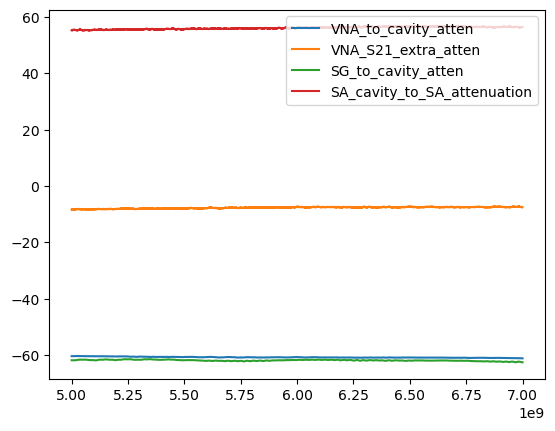

C:\Users\Data Analysis\AppData\Local\Temp\ipykernel_18872\2250797432.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_atten.show()


In [3]:
#attenuation circuit 2:
#%matplotlib notebook
%matplotlib inline
VNA_to_cavity_atten = attenuation_object.load_from_tsv(dir_path + r"Attenuation\circuit_2\processed_data\atten_VNA_to_cavity_atten.tsv")
VNA_S21_extra_atten = attenuation_object.load_from_tsv(dir_path + r"Attenuation\circuit_2\processed_data\atten_VNA_S21_extra_atten.tsv")
SG_to_cavity_atten = attenuation_object.load_from_tsv(dir_path + r"Attenuation\circuit_2\processed_data\atten_SG_to_cavity_atten.tsv")
SA_cavity_to_SA_attenuation = attenuation_object.load_from_tsv(dir_path + r"Attenuation\circuit_2\processed_data\atten_SA_cavity_to_SA_attenuation.tsv")

attens = [VNA_to_cavity_atten, VNA_S21_extra_atten, SG_to_cavity_atten, SA_cavity_to_SA_attenuation]

fig_atten, ax_atten = plt.subplots()



ax_atten.plot(VNA_to_cavity_atten.frequencies, VNA_to_cavity_atten.magnitude, label = "VNA_to_cavity_atten")
ax_atten.plot(VNA_S21_extra_atten.frequencies, VNA_S21_extra_atten.magnitude, label = "VNA_S21_extra_atten")
ax_atten.plot(SG_to_cavity_atten.frequencies, SG_to_cavity_atten.magnitude, label = "SG_to_cavity_atten")
ax_atten.plot(SA_cavity_to_SA_attenuation.frequencies, SA_cavity_to_SA_attenuation.magnitude, label = "SA_cavity_to_SA_attenuation")
ax_atten.legend()
plt.show()
fig_atten.show()

%matplotlib qt


## Import Data


In [4]:
SA_data = []
#load in file
for file in os.listdir(SA_data_path):
    path =   SA_data_path + file
    data_pandas_temp, meta_data_temp = read_file(path)

    meta_data_temp["file_name"] = file
    file_name_split = meta_data_temp["file_name"].split("_")
    file_time = "_".join(file_name_split[0:7])
    print(f"file_time:{file_time}")
    datetime_object = datetime.strptime(file_time, "%Y_%m_%d_%H_%M_%S_%f")  #timestamp_S21 = datetime.now().strftime("%Y_%m_%d_%H_%M_%S_%f")
    timestamp = datetime_object.timestamp()
    meta_data_temp["datetime_object"] = datetime_object
    meta_data_temp["timestamp[s]"] = timestamp

    SA_data.append(
        {
            "data":data_pandas_temp,
            **meta_data_temp
        }
    )
#accounts for missing key values by adding a NAN:
SA_df = pd.json_normalize(SA_data)

print("\n\n\n----------------\n")

print(f"{SA_df.columns=}")
print(f"\n---------\n{SA_df.index=}")




file_time:2025_01_19_07_26_21_750979
file_time:2025_01_19_07_26_21_750979
file_time:2025_01_19_07_26_21_750979
file_time:2025_01_19_07_44_25_013087
file_time:2025_01_19_07_44_25_013087
file_time:2025_01_19_07_44_25_013087
file_time:2025_01_19_08_02_29_209316
file_time:2025_01_19_08_02_29_209316
file_time:2025_01_19_08_02_29_209316
file_time:2025_01_19_08_20_32_742436
file_time:2025_01_19_08_20_32_742436
file_time:2025_01_19_08_20_32_742436
file_time:2025_01_19_08_38_36_503831
file_time:2025_01_19_08_38_36_503831
file_time:2025_01_19_08_38_36_503831
file_time:2025_01_19_08_56_40_009735
file_time:2025_01_19_08_56_40_009735
file_time:2025_01_19_08_56_40_009735
file_time:2025_01_19_09_14_43_284366
file_time:2025_01_19_09_14_43_284366
file_time:2025_01_19_09_14_43_284366
file_time:2025_01_19_09_32_46_608034
file_time:2025_01_19_09_32_46_608034
file_time:2025_01_19_09_32_46_608034
file_time:2025_01_19_09_50_50_206054
file_time:2025_01_19_09_50_50_206054
file_time:2025_01_19_09_50_50_206054
f

In [5]:
S21_data = []
#load in file
for file in os.listdir(S21_data_path):
    path =   S21_data_path + file
    if not ".tsv" in file: continue 
    data_pandas_temp, meta_data_temp = read_file(path)

    meta_data_temp["file_name"] = file

    file_split = file.split("_")
    file_time = file_split[0:7]
    if "VNA_type" in meta_data_temp.keys():
        file_time = file_split[1:8]
    file_time = "_".join(file_time)
    
    datetime_object = datetime.strptime(file_time, "%Y_%m_%d_%H_%M_%S_%f")  #timestamp_S21 = datetime.now().strftime("%Y_%m_%d_%H_%M_%S_%f")
    timestamp = datetime_object.timestamp()
    meta_data_temp["datetime_object"]= datetime_object
    meta_data_temp["timestamp[s]"] = timestamp

    S21_data.append(
        {
            "data":data_pandas_temp,
            **meta_data_temp
        }
    )
#accounts for missing key values by adding a NAN:
S21_df = pd.json_normalize(S21_data)

print("\n\n\n----------------\n")

print(f"{S21_df.columns=}")
print(f"\n---------\n{S21_df.index=}")

#sort S21 data by time timestamp[s], inn place
S21_df.sort_values(by = ["timestamp[s]"], inplace = True)





----------------

S21_df.columns=Index(['data', 'time_start[s]', 'delta_T[s]', 'Result', 'TraceName',
       'freq_start', 'freq_stop', 'number_of_points', 'probe_power',
       'band_width', 'calibration', 'load_state', 'sense_average_state',
       'sense_average_count_factor', 'sense_average_point_count_factor',
       'sense_sweep_type_format', 'reset', '_file_name', 'file_location',
       'extra_meta', 'device_cal', 'sweep_time', 'file_name',
       'datetime_object', 'timestamp[s]', 'VNA_type', 'cavity_pressure',
       'Temperature', 'Vvna_number_of_point', 'Vvna_SA_average_points',
       'Vvna_band_width', 'cent_freq', 'Vvna_span', 'span', 'sweep_points',
       'power', 'save_location'],
      dtype='object')

---------
S21_df.index=RangeIndex(start=0, stop=3656, step=1)


# Data Processing:

## Data Processing functions -> to be moved to device classes asap

# Plot Figure Setup

In [6]:
#Attenuation
fig_plotly_atten = go.Figure()
fig_plotly_atten.update_layout(
title="Attenuation (S21)",
xaxis_title="Frequency(Hz)",
yaxis_title="S21[dB]",
showlegend = True,
)

#S21s
fig_plotly_S21 = go.Figure()
fig_plotly_S21.update_layout(
title="S21[dB]",
xaxis_title="Frequency(Hz)",
yaxis_title="S21[dB]",
showlegend = True,
)


#inidivudal raw PSDs
fig_plotly_raw = go.Figure()
fig_plotly_raw.update_layout(
title="S_ww[dBm]",
xaxis_title="Frequency relative to pump (Hz)",
yaxis_title="PSD[dBm/Hz]",
showlegend = True,
)


#S_xx:
fig_plotly_S_xx = go.Figure()
fig_plotly_S_xx.update_layout(
title="S_xx[m^2/Hz]",
xaxis_title="Frequency relative to pump (Hz)",
yaxis_title="S_xx[m^2/Hz]",
showlegend = True,
)


### misc:

In [7]:
print(f"{SA_df["data"][0]}")

            freq[Hz]  powers[dBm]
0       6.188657e+09  -176.054871
1       6.188657e+09  -161.133835
2       6.188657e+09  -160.690674
3       6.188657e+09  -162.399536
4       6.188657e+09  -164.756393
...              ...          ...
99996   6.188657e+09  -168.023407
99997   6.188657e+09  -168.586883
99998   6.188657e+09  -167.204147
99999   6.188657e+09  -168.983765
100000  6.188657e+09  -170.204895

[100001 rows x 2 columns]


## Data Selection

In [8]:

print(f"{SA_df.index=}")

#print data keys
print(f"{SA_df.columns=}")
print("\n\---------\n")

print(f"{S21_df.columns=}")
print(f"\n---------\n{S21_df.index=}")


SA_df.index=RangeIndex(start=0, stop=180, step=1)
SA_df.columns=Index(['data', 'central_freq', 'span', 'res_band_width', 'sweep_points',
       'sample_rate', 'average_number', 'filter_bandwidth',
       'temperature_mc[k]', 'cavity_pressure[mbar]', 'resonance_freq',
       'freq_pos_offset', 'drive_freq', 'drive_power',
       'piezo_white_noise_drive', 'average_exterior', 'pump_detuning_type',
       'res_bw', 'ref_level', 'ref', 'save', 'file_location', 'file_name',
       'extra_meta', 'reset', 'args', 'kwargs', 'maximum_record_points',
       'record_points', 'IQ_format', 'TRACEIQSET', 'time_trace_length',
       'time_trace_length_max', 'time_trace_points', 'time_trace_func',
       'fft_transform_method', 'fft_trace_mode', 'fft_trace_func',
       'fft_trace_length', 'fft_trace_length_max', 'domain', 'datetime_object',
       'timestamp[s]'],
      dtype='object')

\---------

S21_df.columns=Index(['data', 'time_start[s]', 'delta_T[s]', 'Result', 'TraceName',
       'freq_start'

<>:5: SyntaxWarning:

invalid escape sequence '\-'

<>:5: SyntaxWarning:

invalid escape sequence '\-'

C:\Users\Data Analysis\AppData\Local\Temp\ipykernel_18872\2099555048.py:5: SyntaxWarning:

invalid escape sequence '\-'



In [9]:
#select data
#data should be in comparable format to meta data
#key should be exact key from meta data
#please select one set of data to be averaged, e.g one power

select = {
    "drive_power": ["0"],
    "domain":["freq"]
}

loop = ["-10", "-5", "0", "1", "2", "3"]


## to be moved to device classes

## Data Processing

In [ ]:
h_bar = 1.054571817e-34

##Add m_eff to SA_df

fig,ax = plt.subplots()
ax.set(title = r"Thermal Motion PSD", xlabel = r"Frequency[Hz]", ylabel = r"$S_{xx}[\rm{m}^2/\rm{Hz}]$")


for i in loop:
    select["drive_power"] = [i]
    m_eff = 43.28/(434.5**2) #for 14KHz mode


    ##averaage_and_fit_Sxx
    output_dict = fit_S_xx.__average_and_fit_S_xx__(SA_df, select, m_eff, S21_df, VNA_S21_extra_atten, SA_cavity_to_SA_attenuation, SG_to_cavity_atten )
    """"S21_power_attenuated":S21_powers,
        "S21_freqs":S21_freqs,
        "S21_linear_voltage_fitted":S21_linear_voltage_fitted,
        "S21_freq_fitted":S21_freq_fitted,
        "popt_S21":popt_S21,
        "pcov_S21":pcov_S21,
        "S21_eq":S21_eq,
        "n_d":n_d,
        "GGS_xx":GGS_xx,
        "S_xx_freqs_temp":S_xx_freqs_temp,
        "NENBW":NENBW,
        
        "SG_drive_power":drive_power,
        "P_in_dBm":drive_power_at_cavity,
        "P_in_W":linear_drive_power_at_cavity,
        "T":T,
        "S_xx":S_xx, 
        "S_xx_freqs":S_xx_freqs, 
        "popt_S_xx":popt_S_xx, 
        "pcov_S_xx":pcov_S_xx, 
        "S_xx_fit":S_xx_fit, 
        "GG_S_norm_fit":GG_S_norm_fit, 
        "variables_df_mean":variables_df_mean, 
        "GGSxx_dict":GGSxx_dict, 
        "GG_S_norm_avg":GG_S_norm_avg, 
        "GG_S_norm_sig":GG_S_norm_sig,
    """

    S_xx_freqs      = output_dict["S_xx_freqs"]
    S_xx            = output_dict["S_xx"]
    S_xx_fit        = output_dict["S_xx_fit"]
    SG_drive_power  = output_dict["SG_drive_power"]
    GG_S_norm_list  = output_dict["GG_S_norm_list"]
    g_0             = output_dict["g_0"]
    G               = output_dict["G"]
    x_zpf           = output_dict["x_zpf"]
    variables_df_mean=output_dict["variables_df_mean"]
    f_m, G_m, A, c  = output_dict["popt_S_xx"]
    f_c, k_tot, k_ext, mx_S21, c_S21, n_d, P_in, T = output_dict["variables_df_mean"]

    S21_powers_fitted_list = output_dict["S21_powers_list"]
    S21_freqs_fitted_list = output_dict["S21_freqs_fitted_list"]

    S_ww_raw_list = output_dict["S_ww_raw_list"]
    S_ww_raw_freqs_list = output_dict["S_ww_raw_freqs_list"]
    S_ww_index_order = output_dict["S_ww_index_order"]

    variables_list = output_dict["variables_list"]


    #plot
    for i in range(np.shape(S_ww_raw_list)[0]):
        fig_plotly_raw.add_trace(go.Scatter(x=S_ww_raw_freqs_list[i], y=S_ww_raw_list[i], mode='lines',
                                    name=f"{SG_drive_power=},index:{S_ww_index_order[i]} f_m:{f_m}",
                                    ))
    
        f_c = variables_list[i]["f_c"]
        k_tot = variables_list[i]["k_tot"]
        k_ext = variables_list[i]["k_ext"]
        mx_S21 = variables_list[i]["mx_S21"]
        c_S21 = variables_list[i]["c_S21"]

        popt_S21 = [f_c, k_tot, k_ext, mx_S21, c_S21]
        fig_plotly_S21.add_trace(go.Scatter(x=S21_freqs_fitted_list[i], y=linear_voltage_to_dB(S21_eq(S21_freqs_fitted_list[i],*popt_S21)), mode='lines',
                                        name=f"fit:,index:{S_ww_index_order[i]}, fc{f_c:.3e}, kt:{k_tot:.3e}, ke:{k_ext:.3e}",
                                        ))
        
        fig_plotly_S21.add_trace(go.Scatter(x=S21_freqs_fitted_list[i], y=S21_powers_fitted_list[i], mode='lines',
                                    name=f"data:index:{S_ww_index_order}",
                                    ))
        
    

    ##Final Plots:

    p = ax.plot(S_xx_freqs, S_xx, "x-")
    ax.plot(S_xx_freqs, S_xx_fit, "-", color = p[-1].get_color(),
            label = f"fit: Drive Pwr:{SG_drive_power}dB, g_0:{g_0:.3e}, f_m:{f_m:.3e},"\
              f"G_m:{G_m:.3e}, T:{T:.3e}, n_d:{variables_df_mean["n_d"]}")
    fig.tight_layout()
    ax.legend()
    
    #plot
    fig_plotly_S_xx.add_trace(go.Scatter(x=S_xx_freqs, y=S_xx, mode='lines',
                            name=f"data:Drive Pwr:{SG_drive_power}dB, g_0:{g_0:.3e}, f_m:{f_m:.3e}, G_m:{G_m:.3e}, T:{T:.3e}, n_d:{variables_df_mean["n_d"]:.3e}, fc{f_c:.3e}, kt:{k_tot:.3e}, ke:{k_ext:.3e}",
                            ))
    fig_plotly_S_xx.add_trace(go.Scatter(x=S_xx_freqs, y=S_xx_fit, mode='lines',
                            name=f"fit: Drive Pwr:{SG_drive_power}dB, g_0:{g_0:.3e}, f_m:{f_m:.3e}, G_m:{G_m:.3e}, T:{T:.3e}, n_d:{variables_df_mean["n_d"]:.3e}, fc{f_c:.3e}, kt:{k_tot:.3e}, ke:{k_ext:.3e}",
                            ))





    

selected: index=0,key='domain',['freq']
drive_power=-10.0
warning no errors
warning no errors
warning no errors
selected: index=3,key='domain',['freq']
drive_power=-10.0
warning no errors
warning no errors
warning no errors
selected: index=6,key='domain',['freq']
drive_power=-10.0
warning no errors
warning no errors
warning no errors
selected: index=9,key='domain',['freq']
drive_power=-10.0
warning no errors
warning no errors
warning no errors
selected: index=12,key='domain',['freq']
drive_power=-10.0
warning no errors
warning no errors
warning no errors
selected: index=15,key='domain',['freq']
drive_power=-10.0
warning no errors
warning no errors
warning no errors
selected: index=18,key='domain',['freq']
drive_power=-10.0
warning no errors
warning no errors
warning no errors
selected: index=21,key='domain',['freq']
drive_power=-10.0
warning no errors
warning no errors
warning no errors
selected: index=24,key='domain',['freq']
drive_power=-10.0
warning no errors
warning no errors
warni

## Attenuation Plots

In [11]:
fig_plotly_atten.add_trace(go.Scatter(x=VNA_to_cavity_atten.frequencies, y=VNA_to_cavity_atten.magnitude, mode='lines',
                            name=f"VNA_to_cavity_atten",
                            ))
fig_plotly_atten.add_trace(go.Scatter(x=VNA_S21_extra_atten.frequencies, y=VNA_S21_extra_atten.magnitude, mode='lines',
                            name=f"VNA_S21_extra_atten",
                            ))
fig_plotly_atten.add_trace(go.Scatter(x=SG_to_cavity_atten.frequencies, y=SG_to_cavity_atten.magnitude, mode='lines',
                            name=f"SG_to_cavity_atten",
                            ))
fig_plotly_atten.add_trace(go.Scatter(x=SA_cavity_to_SA_attenuation.frequencies, y=SA_cavity_to_SA_attenuation.magnitude, mode='lines',
                            name=f"SA_cavity_to_SA_attenuation",
                            ))

## Save Plots

In [12]:
file_name_gen = "Plotly.html"
fig_plotly_atten.write_html("atten"+file_name_gen)
fig_plotly_raw.write_html("raw"+file_name_gen)
fig_plotly_S21.write_html("S21"+file_name_gen)
fig_plotly_S_xx.write_html("S_xx"+file_name_gen)


##matplotlib:
fig.savefig("S_xx_plotly.pdf")